# Modularity on the Karate Club Graph
**DSC212: Graph Theory Module — Research Assignment**

This notebook implements **recursive spectral modularity partitioning** from scratch (NumPy + NetworkX only) on Zachary's Karate Club network, following the assignment handout and Newman (2006).

**Pipeline**
1. Load the graph and build the modularity matrix $B = A - \frac{k k^\top}{2m}$.
2. Bisect a community $C$ with the sign of the leading eigenvector of $B^{(C)}$ (Newman's generalised matrix $B^{(C)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il}$, i.e. the block of $B$ with Newman's diagonal correction; see Section 3 for why it is needed); stop when $\lambda_1^{(C)} \le 0$ or the split would not increase $Q$.
3. Visualise the graph after every split (fixed spring layout, one colour per community, node IDs as labels).
4. After every split compute degree, betweenness and closeness centrality and the clustering coefficient with NetworkX.
5. Plot how every metric evolves per node across iterations and discuss.

**Conventions used (stated explicitly so the results are reproducible)**
- *Iteration 0* is the whole graph as one community; *iteration t* is the state right after the $t$-th successful split. Communities are processed first-in-first-out.
- Node metrics after each split are computed **within each node's current community** (on the induced subgraph `G.subgraph(C)`), because metrics on the full graph would not change between iterations. The full-graph values are exactly the iteration-0 values.
- **Node numbering:** nodes are numbered **1–34** everywhere in this notebook (printed output, plot labels, legends, tables and text). NetworkX stores them as 0–33, so every displayed id is the internal id + 1.
- All graph objects are treated as **unweighted** (`weight=None`), matching the handout's $A_{ij}\in\{0,1\}$.

## 1. Setup and data

In [1]:
import os
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True, linewidth=120)
os.makedirs("assets", exist_ok=True)   # figures are also saved here for the repository

TOL = 1e-10     # numerical tolerance used for the test  lambda_1 <= 0

In [2]:
G = nx.karate_club_graph()
nodes = sorted(G.nodes())                       # 0, 1, ..., 33
n, m = G.number_of_nodes(), G.number_of_edges()

# Adjacency matrix. weight=None forces a 0/1 matrix (some NetworkX versions attach edge weights).
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
k = A.sum(axis=1)                               # degree vector

assert n == 34 and m == 78
assert set(np.unique(A)) <= {0.0, 1.0} and np.allclose(A, A.T)
assert np.isclose(k.sum(), 2 * m)
print(f"n = {n} nodes, m = {m} edges, sum of degrees = {int(k.sum())} (= 2m)")

# Ground truth: the real split of the club (stored by NetworkX as the 'club' node attribute)
truth = np.array([1 if G.nodes[i]["club"] == "Mr. Hi" else -1 for i in nodes])
print("Mr. Hi's faction:", [i + 1 for i in nodes if truth[i] == 1])
print("Officer's faction:", [i + 1 for i in nodes if truth[i] == -1])

n = 34 nodes, m = 78 edges, sum of degrees = 156 (= 2m)
Mr. Hi's faction: [1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12, 13, 14, 17, 18, 20, 22]
Officer's faction: [10, 15, 16, 19, 21, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34]


## 2. The modularity matrix
$B_{ij} = A_{ij} - \dfrac{k_i k_j}{2m}$. We check Proposition 1 (real symmetric) and Proposition 2 ($B\mathbf 1 = 0$).

In [3]:
B = A - np.outer(k, k) / (2 * m)

print("B is symmetric            :", np.allclose(B, B.T))
print("max |B @ 1|  (should be 0):", np.abs(B @ np.ones(n)).max())
w = np.linalg.eigvalsh(B)
print("largest eigenvalues of B  :", w[::-1][:4])
print("trivial partition Q = 1'B1/(4m) =", np.ones(n) @ B @ np.ones(n) / (4 * m))

B is symmetric            : True
max |B @ 1|  (should be 0): 8.881784197001252e-16
largest eigenvalues of B  : [4.9771 3.0428 2.3202 1.4888]
trivial partition Q = 1'B1/(4m) = 8.718097469011646e-18


## 3. Spectral bisection and recursive splitting

`bisect(C)` tries to split a community $C$ (a set of nodes) in two, using the leading eigenvector of the modularity matrix of the subgroup.

### Newman's correction for a subgroup (formula used)
For the whole graph the modularity matrix is $B_{ij}=A_{ij}-\dfrac{k_ik_j}{2m}$. For a subgroup $C$ we do **not** use the plain block of $B$. We use Newman's generalised modularity matrix (Newman 2006, eq. 6):

$$\boxed{\,B^{(C)}_{ij}\;=\;B_{ij}\;-\;\delta_{ij}\sum_{l\in C}B_{il},\qquad i,j\in C\,}$$

that is, the block of $B$ indexed by $C$ with each row sum subtracted on the diagonal. In the code this is `B_C -= np.diag(B_C.sum(axis=1))`.

**Why this correction is necessary.** Splitting $C$ into two parts changes the total modularity by
$$\Delta Q=\frac{1}{4m}\,s^\top B^{(C)}s,$$
and this identity holds *only* for the corrected matrix. The plain block ignores the ties that connect nodes of $C$ to the rest of the graph, so $s^\top(\text{plain block})\,s$ over-states the gain, and its leading eigenvalue is typically positive even for a group that has no internal structure left. The correction restores the property $B^{(C)}\mathbf 1=\mathbf 0$ (every row sums to zero, exactly as for the full $B$ in Proposition 2), so an indivisible group has $\lambda_1=0$ and the rule "stop when $\lambda_1\le 0$" (Theorem 3) means what it says. Section 4 demonstrates the failure of the plain block on this very graph (node 12).

### Procedure
1. Build $B^{(C)}$ as above and take its leading eigenpair with `numpy.linalg.eigh` (real symmetric matrix, so real eigenvalues and orthonormal eigenvectors; eigenvalues come back in ascending order, so the leading pair is the last one).
2. If $\lambda_1^{(C)}\le 0$, $C$ is **indivisible**: return `None`.
3. Otherwise split by the sign of $u_1$: $s_i=+1$ if $(u_1)_i>0$, else $-1$.
4. Guard: if the *thresholded* split has $\Delta Q=\frac{1}{4m}s^\top B^{(C)}s\le 0$ (or one side is empty), reject it. The eigenvalue test alone does not guarantee that the rounded $\pm1$ vector improves $Q$.

The sign of an eigenvector is arbitrary, so we fix it by making the largest-magnitude entry positive (this only decides which child is called "+").

`modularity(partition)` uses $Q=\frac{1}{2m}\sum_{C}\sum_{i,j\in C}B_{ij}$ with the *original* $B$, which for two groups equals $\frac{1}{4m}s^\top Bs$ (eq. 1 of the handout).

In [4]:
def leading_eigenpair(M):
    # Leading (largest) eigenvalue and unit eigenvector of a real symmetric matrix.
    vals, vecs = np.linalg.eigh(M)               # ascending order
    lam, u = vals[-1], vecs[:, -1]
    if u[np.argmax(np.abs(u))] < 0:              # deterministic sign convention
        u = -u
    return lam, u


def bisect(C):
    # Try to split community C (list of node ids). Returns (parts, lam1, u1); parts is None if indivisible.
    C = list(C)
    B_C = B[np.ix_(C, C)].copy()                 # block of B indexed by C
    # Newman's correction (necessary): B^(C)_ij = B_ij - delta_ij * sum_{l in C} B_il.
    # Subtracting the row sums on the diagonal makes s' B^(C) s / (4m) the TRUE change in Q and B^(C) @ 1 = 0.
    B_C -= np.diag(B_C.sum(axis=1))
    lam1, u1 = leading_eigenpair(B_C)
    if lam1 <= TOL:                              # stopping rule (Theorem 3)
        return None, lam1, u1
    s = np.where(u1 > 0, 1, -1)                  # threshold back to {-1, +1}
    C_plus  = [C[i] for i in range(len(C)) if s[i] == 1]
    C_minus = [C[i] for i in range(len(C)) if s[i] == -1]
    if len(C_plus) == 0 or len(C_minus) == 0:    # degenerate: all signs equal -> no real split
        return None, lam1, u1
    dQ = s @ B_C @ s / (2 * m) / 2               # modularity change of the thresholded split: s' B^(C) s / (4m)
    if dQ <= TOL:                                # thresholding destroyed the gain -> reject the split
        return None, lam1, u1
    return (C_plus, C_minus), lam1, u1


def modularity(communities):
    # Q = (1/2m) * sum over communities of the sum of B_ij inside the community.
    return sum(B[np.ix_(c, c)].sum() for c in communities) / (2 * m)


METRICS = ["degree", "betweenness", "closeness", "clustering"]

def community_metrics(G, communities):
    # The four NetworkX metrics, computed inside each community (induced subgraph).
    out = {name: {} for name in METRICS}
    for C in communities:
        H = G.subgraph(C)
        out["degree"].update(nx.degree_centrality(H))
        out["betweenness"].update(nx.betweenness_centrality(H))
        out["closeness"].update(nx.closeness_centrality(H))
        out["clustering"].update(nx.clustering(H))
    return {name: np.array([out[name][i] for i in nodes]) for name in METRICS}

### Recursive bisection driver
Start from the full vertex set; repeatedly pop a community, try to split it, and push both halves back on the queue. The "+" child keeps the parent's community id (so its colour is stable in the plots); the "−" child gets a new id. After every successful split we store a snapshot: partition, $Q$ and the four metrics.

In [5]:
comm = {0: list(nodes)}          # community id -> list of nodes
queue, next_id = [0], 1
final_ids, attempts = [], []     # communities declared indivisible; log of every eigenvalue test

def snapshot(it, event):
    parts = [comm[c] for c in sorted(comm)]
    return {
        "iter": it,
        "event": event,
        "label": {i: cid for cid, C in comm.items() for i in C},   # node -> community id
        "parts": {cid: list(C) for cid, C in comm.items()},
        "Q": modularity(parts),
        "metrics": community_metrics(G, parts),
    }

history = [snapshot(0, "whole graph (one community)")]
it = 0
while queue:
    cid = queue.pop(0)
    parts, lam1, u1 = bisect(comm[cid])
    size = len(comm[cid])
    if parts is None:
        final_ids.append(cid)
        attempts.append((cid, size, lam1, "stop (indivisible)"))
        continue
    C_plus, C_minus = parts
    comm[cid], comm[next_id] = C_plus, C_minus
    attempts.append((cid, size, lam1, f"split -> {len(C_plus)} + {len(C_minus)}  (new id {next_id})"))
    queue += [cid, next_id]
    next_id += 1
    it += 1
    history.append(snapshot(it, f"split community {cid} ({size} nodes) -> {len(C_plus)} + {len(C_minus)}"))

print(f"{it} successful splits, {len(comm)} final communities\n")
print(f"{'community':>9} {'size':>5} {'lambda_1':>10}   decision")
for cid, size, lam1, decision in attempts:
    print(f"{cid:>9} {size:>5} {lam1:>10.4f}   {decision}")

3 successful splits, 4 final communities

community  size   lambda_1   decision
        0    34     4.9771   split -> 16 + 18  (new id 1)
        0    16     1.1785   split -> 9 + 7  (new id 2)
        1    18     0.8594   split -> 6 + 12  (new id 3)
        0     9     0.0602   stop (indivisible)
        2     7    -0.0000   stop (indivisible)
        1     6     0.0000   stop (indivisible)
        3    12    -0.0000   stop (indivisible)


## 4. Results of the partitioning

In [6]:
print(f"{'iter':>4} {'#comm':>6} {'Q':>8}   sizes / event")
for h in history:
    sizes = sorted((len(C) for C in h["parts"].values()), reverse=True)
    print(f"{h['iter']:>4} {len(h['parts']):>6} {h['Q']:>8.4f}   {sizes}  | {h['event']}")

# First split (iteration 1) versus the real split of the club
first = history[1]["parts"]
side = np.array([1 if i in first[0] else -1 for i in nodes])
if (side == truth).sum() < n / 2:                # community labels are arbitrary -> pick the better orientation
    side = -side
wrong = [i for i in nodes if side[i] != truth[i]]
print(f"First split reproduces the real club split for {n - len(wrong)}/{n} members; misplaced node(s): {[i + 1 for i in wrong]}")

print("\nFinal communities (node IDs 1-34):")
for cid, C in sorted(history[-1]["parts"].items()):
    print(f"  community {cid} ({len(C)} nodes): {[i + 1 for i in sorted(C)]}")

iter  #comm        Q   sizes / event
   0      1  -0.0000   [34]  | whole graph (one community)
   1      2   0.3715   [18, 16]  | split community 0 (34 nodes) -> 16 + 18
   2      3   0.3727   [18, 9, 7]  | split community 0 (16 nodes) -> 9 + 7
   3      4   0.3934   [12, 9, 7, 6]  | split community 1 (18 nodes) -> 6 + 12
First split reproduces the real club split for 33/34 members; misplaced node(s): [9]

Final communities (node IDs 1-34):
  community 0 (9 nodes): [2, 3, 4, 8, 13, 14, 18, 20, 22]
  community 1 (6 nodes): [24, 25, 26, 28, 29, 32]
  community 2 (7 nodes): [1, 5, 6, 7, 11, 12, 17]
  community 3 (12 nodes): [9, 10, 15, 16, 19, 21, 23, 27, 30, 31, 33, 34]


### Why the correction was necessary: the same recursion with the plain block
For comparison only (nothing below is used later), here is the identical recursion with the *plain* block $B_{ij}$ ($i,j\in C$) and **no** diagonal correction, stopping only at $\lambda_1\le 0$ as in the handout. We follow node **12**, which has a single tie (to node 1).

In [7]:
def recursion_plain_block():
    # Same procedure as above, but with the uncorrected block of B (no diagonal term).
    pending, final, rows = [list(nodes)], [], []
    while pending:
        C = pending.pop(0)
        if len(C) < 2:
            final.append(C); continue
        lam1, u1 = leading_eigenpair(B[np.ix_(C, C)])            # plain block
        if lam1 <= TOL:
            final.append(C); continue
        s = np.where(u1 > TOL, 1, -1)
        Cp = [C[i] for i in range(len(C)) if s[i] == 1]
        Cm = [C[i] for i in range(len(C)) if s[i] == -1]
        if not Cp or not Cm:                                      # degenerate: cannot split
            final.append(C); continue
        pending += [Cp, Cm]
        rows.append((len(C), lam1, len(Cp), len(Cm), modularity(final + pending), Cp, Cm))
    return final, rows

final_plain, rows_plain = recursion_plain_block()

print("Plain block (no correction): every split that was made")
print(f"{'split':>5} {'|C|':>4} {'lambda_1':>9}   {'parts':>9}   {'Q after':>8}")
for t_, (size, lam1, a_, b_, q, Cp, Cm) in enumerate(rows_plain, 1):
    print(f"{t_:>5} {size:>4} {lam1:>9.4f}   {a_:>4}+{b_:<4}   {q:>8.4f}")

print(f"\nPlain block: {len(final_plain)} communities, Q = {modularity(final_plain):.4f}")
for C in sorted(final_plain, key=min):
    print(f"   ({len(C):2d} nodes) {[i + 1 for i in sorted(C)]}")

v = 11   # internal id of node 12
print(f"\nNode 12 has degree {int(k[v])}; its only neighbour is node {[w + 1 for w in G.neighbors(v)][0]}.")
where = lambda parts: sorted(next(C for C in parts if v in C))
print("  plain block :", "node 12 ends up ALONE ->", [i + 1 for i in where(final_plain)])
print("  corrected   : node 12 stays with its neighbour ->", [i + 1 for i in where(list(history[-1]['parts'].values()))])
print(f"\nFinal Q: plain block = {modularity(final_plain):.4f} ({len(final_plain)} communities) | "
      f"with Newman's correction = {history[-1]['Q']:.4f} ({len(history[-1]['parts'])} communities)")

Plain block (no correction): every split that was made
split  |C|  lambda_1       parts    Q after
    1   34    4.9771     16+18       0.3715
    2   16    2.9441     10+6        0.3898
    3   18    2.5041     13+5        0.4081
    4    6    2.1480      5+1        0.4094

Plain block: 5 communities, Q = 0.4094
   (10 nodes) [1, 2, 3, 4, 8, 13, 14, 18, 20, 22]
   ( 5 nodes) [5, 6, 7, 11, 17]
   (13 nodes) [9, 10, 15, 16, 19, 21, 23, 24, 27, 30, 31, 33, 34]
   ( 1 nodes) [12]
   ( 5 nodes) [25, 26, 28, 29, 32]

Node 12 has degree 1; its only neighbour is node 1.
  plain block : node 12 ends up ALONE -> [12]
  corrected   : node 12 stays with its neighbour -> [1, 5, 6, 7, 11, 12, 17]

Final Q: plain block = 0.4094 (5 communities) | with Newman's correction = 0.3934 (4 communities)


## 5. Visualisation after each split
One fixed spring layout (`seed=42`) is reused for every plot so that only the colouring changes. Solid grey edges lie inside a community; dashed edges cross between communities.

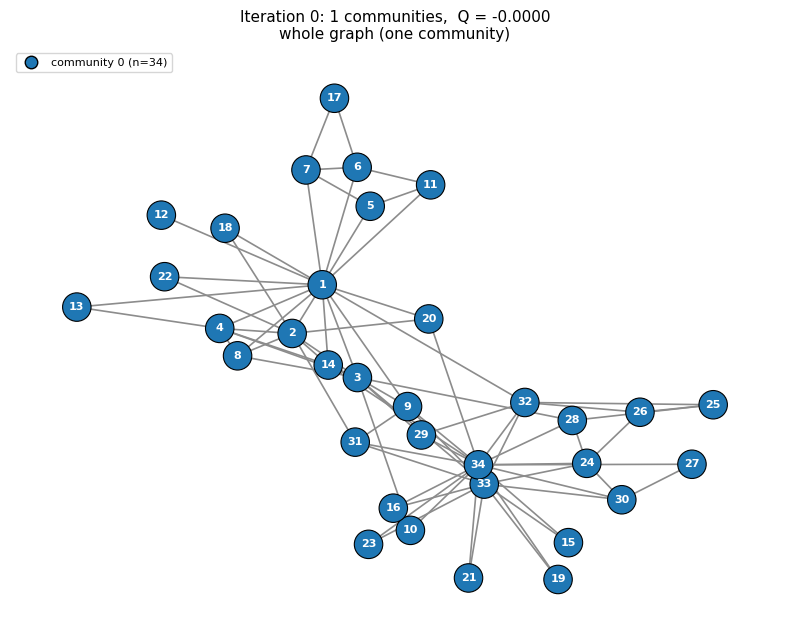

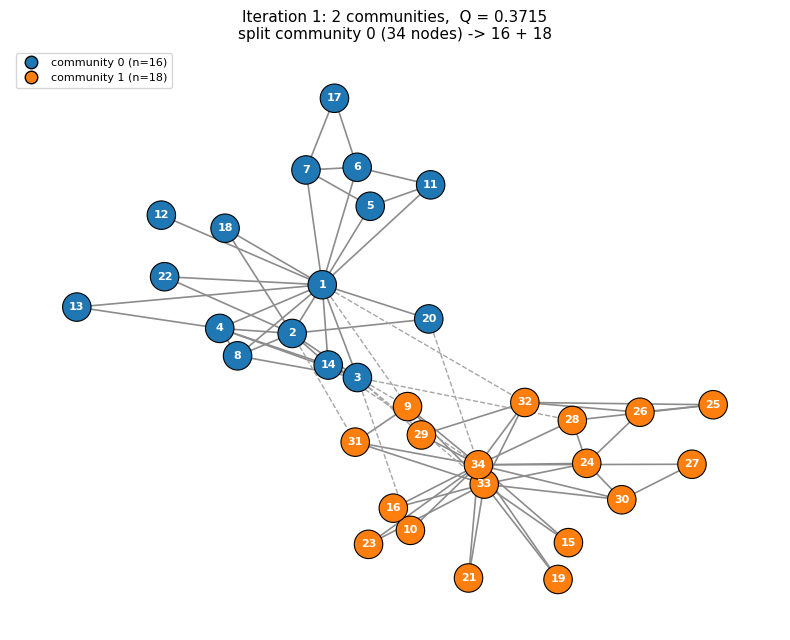

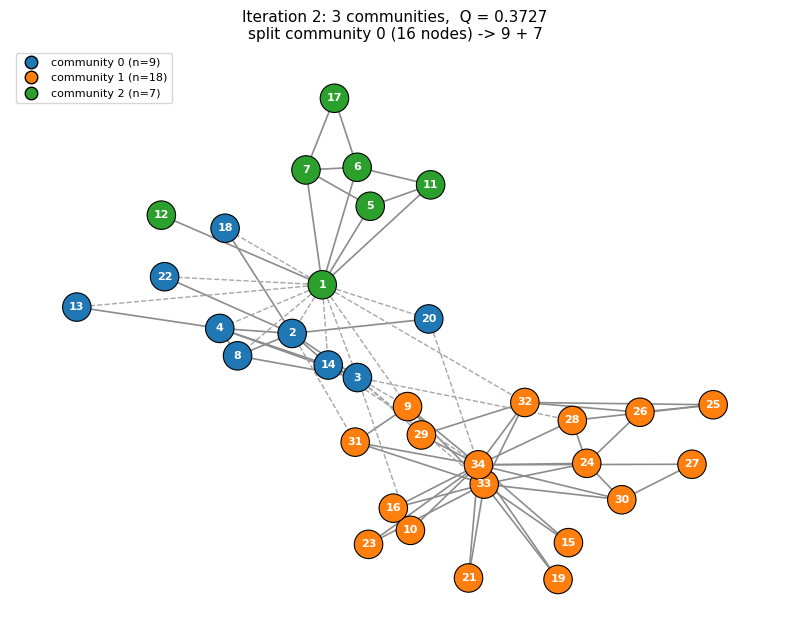

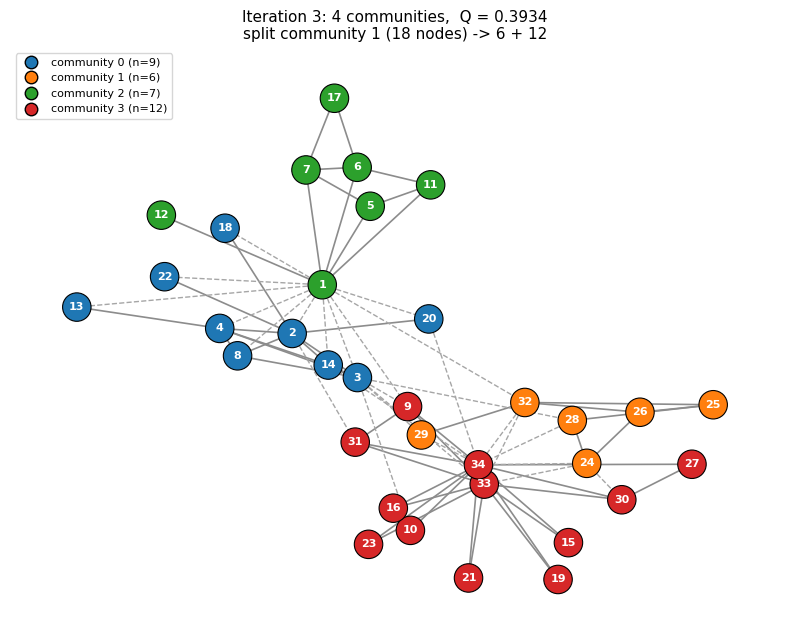

In [8]:
pos = nx.spring_layout(G, seed=42)               # computed ONCE and reused
cmap = plt.get_cmap("tab10")
color_of = lambda cid: cmap(cid % 10)

def draw_snapshot(h):
    fig, ax = plt.subplots(figsize=(8, 6.5))
    lab = h["label"]
    inside  = [(u, v) for u, v in G.edges() if lab[u] == lab[v]]
    between = [(u, v) for u, v in G.edges() if lab[u] != lab[v]]
    nx.draw_networkx_edges(G, pos, edgelist=inside,  edge_color="0.55", width=1.2, ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=between, edge_color="0.65", width=1.0, style="dashed", ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_color=[color_of(lab[i]) for i in nodes],
                           node_size=420, edgecolors="black", linewidths=0.8, ax=ax)
    nx.draw_networkx_labels(G, pos, labels={i: i + 1 for i in nodes}, font_size=8, font_color="white", font_weight="bold", ax=ax)
    handles = [plt.Line2D([], [], marker="o", ls="", markersize=9, markerfacecolor=color_of(cid),
                          markeredgecolor="black", label=f"community {cid} (n={len(C)})")
               for cid, C in sorted(h["parts"].items())]
    ax.legend(handles=handles, loc="upper left", fontsize=8, frameon=True)
    ax.set_title(f"Iteration {h['iter']}: {len(h['parts'])} communities,  Q = {h['Q']:.4f}\n{h['event']}", fontsize=11)
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(f"assets/partition_iter{h['iter']}.png", dpi=150)
    plt.show()

for h in history:
    draw_snapshot(h)

## 6. Node metrics after each split
For every iteration the four metrics are computed for all 34 nodes inside their community (iteration 0 = the full graph).
Below: the 5 highest-scoring nodes for every metric at every iteration, and the mean metric value over the graph.

In [9]:
n_iter = len(history)
M = {name: np.vstack([h["metrics"][name] for h in history]) for name in METRICS}   # shape (n_iter, n)

def top_set(values, r=5):
    # Indices of the r largest values, including every node tied with the r-th value.
    thr = np.sort(values)[::-1][r - 1]
    return [int(i) for i in np.where(values >= thr - 1e-12)[0]]

for name in METRICS:
    print(f"== {name} ==")
    for t in range(n_iter):
        v = M[name][t]
        order = [int(i) for i in np.argsort(-v, kind="stable")[:5]]
        ties = len(top_set(v)) - 5
        note = f"   [+{ties} more tied at the cut-off]" if ties > 0 else ""
        print(f"  iter {t}: mean = {v.mean():.4f} | top 5: " + ", ".join(f"{i + 1} ({v[i]:.3f})" for i in order) + note)

print("\nNodes in the top 5 (ties included) at EVERY iteration:")
for name in METRICS:
    common = set.intersection(*[set(top_set(M[name][t])) for t in range(n_iter)])
    print(f"  {name:12s}: {[i + 1 for i in sorted(common)]}")

== degree ==
  iter 0: mean = 0.1390 | top 5: 34 (0.515), 1 (0.485), 33 (0.364), 3 (0.303), 2 (0.273)
  iter 1: mean = 0.2505 | top 5: 1 (0.933), 34 (0.882), 33 (0.647), 2 (0.533), 4 (0.400)
  iter 2: mean = 0.3245 | top 5: 34 (0.882), 2 (0.875), 1 (0.833), 6 (0.667), 7 (0.667)
  iter 3: mean = 0.3981 | top 5: 34 (1.000), 2 (0.875), 1 (0.833), 33 (0.818), 6 (0.667)   [+1 more tied at the cut-off]
== betweenness ==
  iter 0: mean = 0.0440 | top 5: 1 (0.438), 34 (0.304), 33 (0.145), 3 (0.144), 32 (0.138)
  iter 1: mean = 0.0568 | top 5: 1 (0.690), 34 (0.570), 33 (0.201), 32 (0.113), 2 (0.074)
  iter 2: mean = 0.0785 | top 5: 2 (0.655), 34 (0.570), 1 (0.378), 4 (0.262), 33 (0.201)
  iter 3: mean = 0.1024 | top 5: 2 (0.655), 34 (0.564), 32 (0.400), 1 (0.378), 4 (0.262)
== closeness ==
  iter 0: mean = 0.4265 | top 5: 1 (0.569), 3 (0.559), 34 (0.550), 32 (0.541), 9 (0.516)   [+2 more tied at the cut-off]
  iter 1: mean = 0.5558 | top 5: 1 (0.938), 34 (0.895), 33 (0.739), 2 (0.652), 4 (0.600

### Evolution of every metric
For each metric: **left**, one line per node across iterations (the 5 nodes with the highest average value are coloured and labelled, all others are thin grey lines); **right**, a node × iteration heat-map showing all 34 nodes.

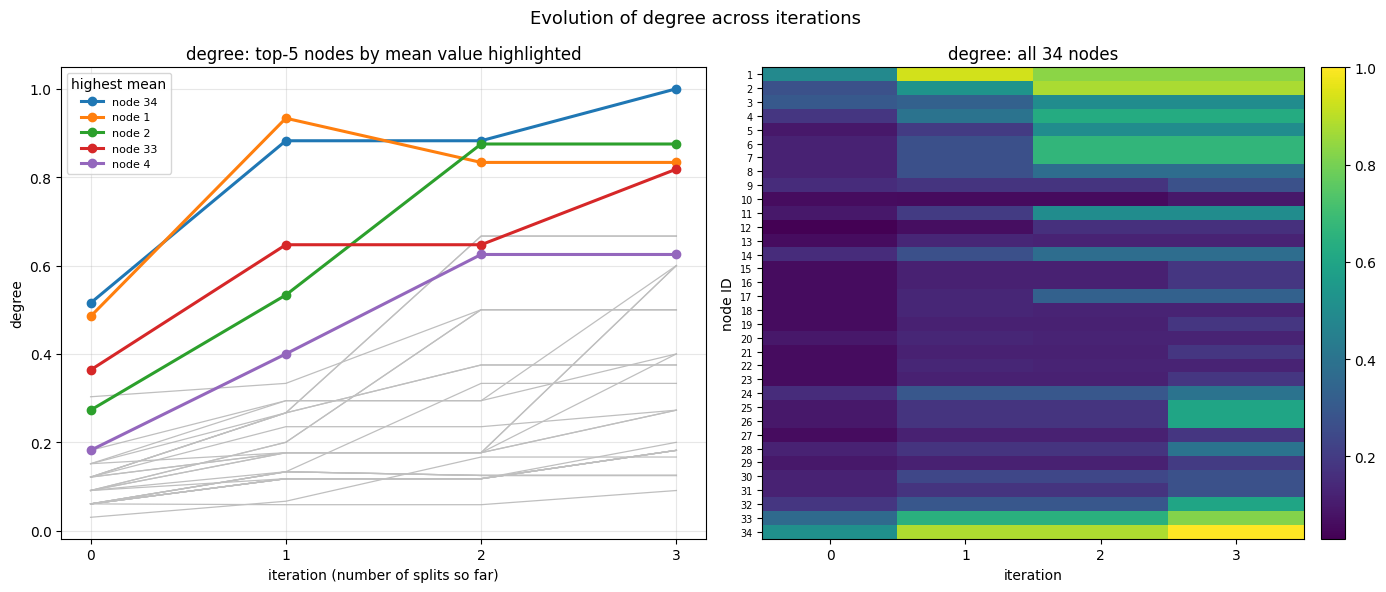

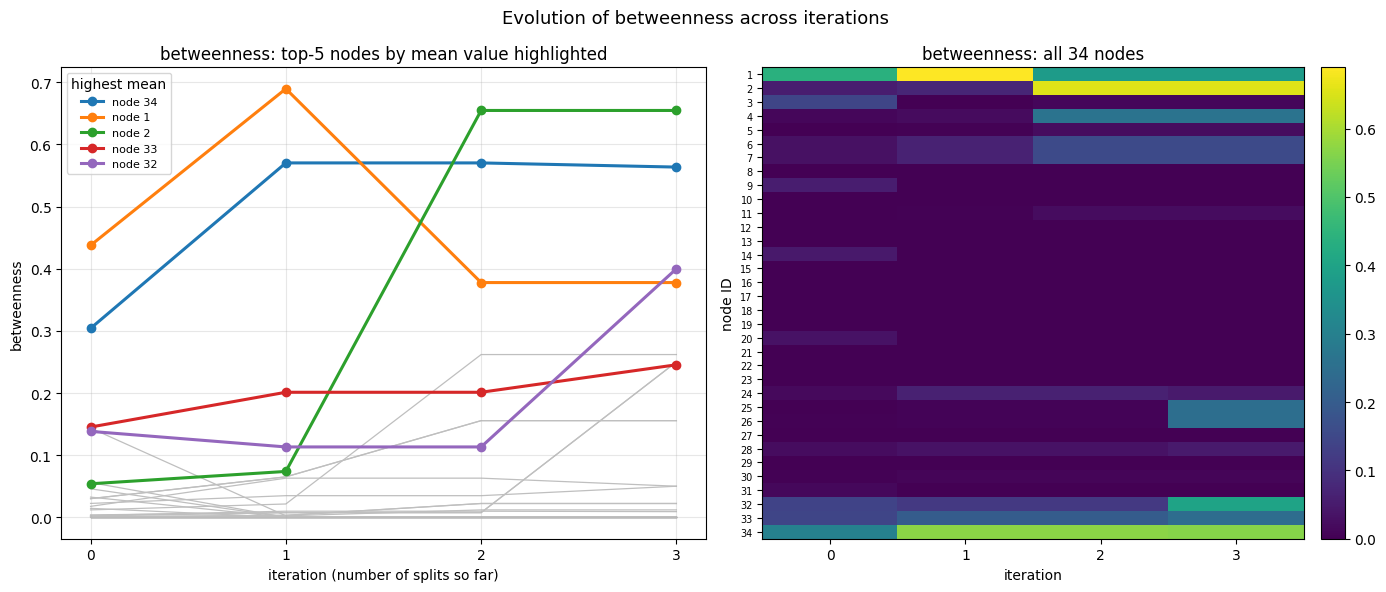

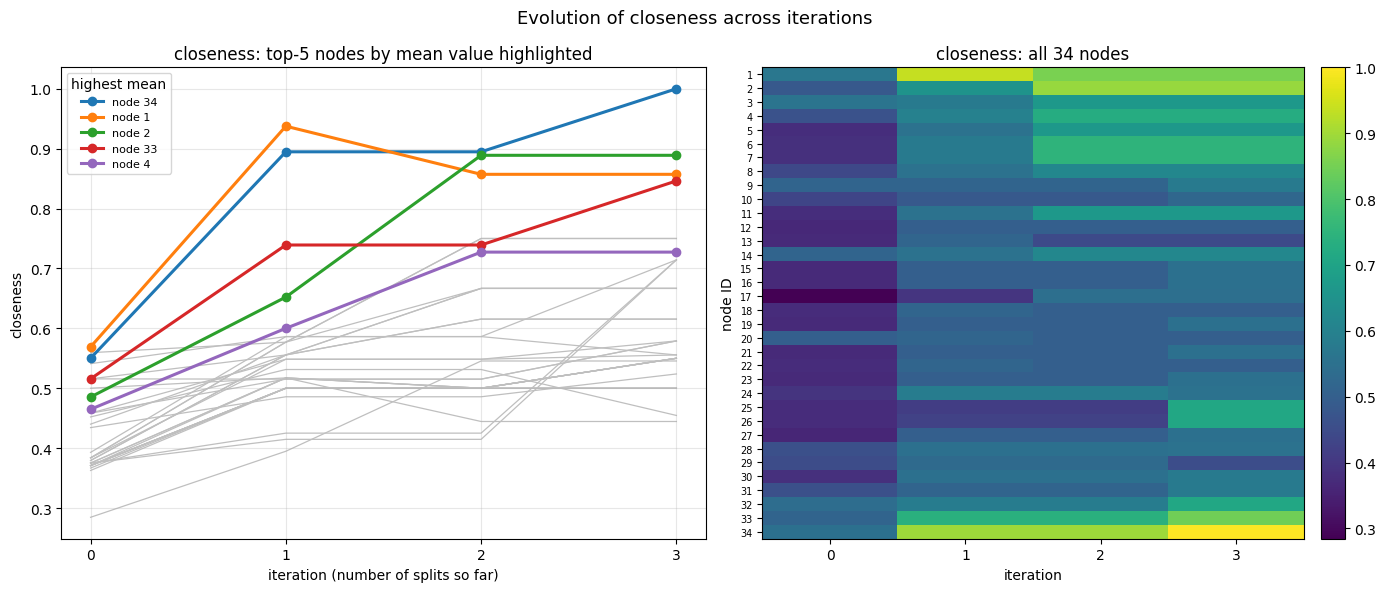

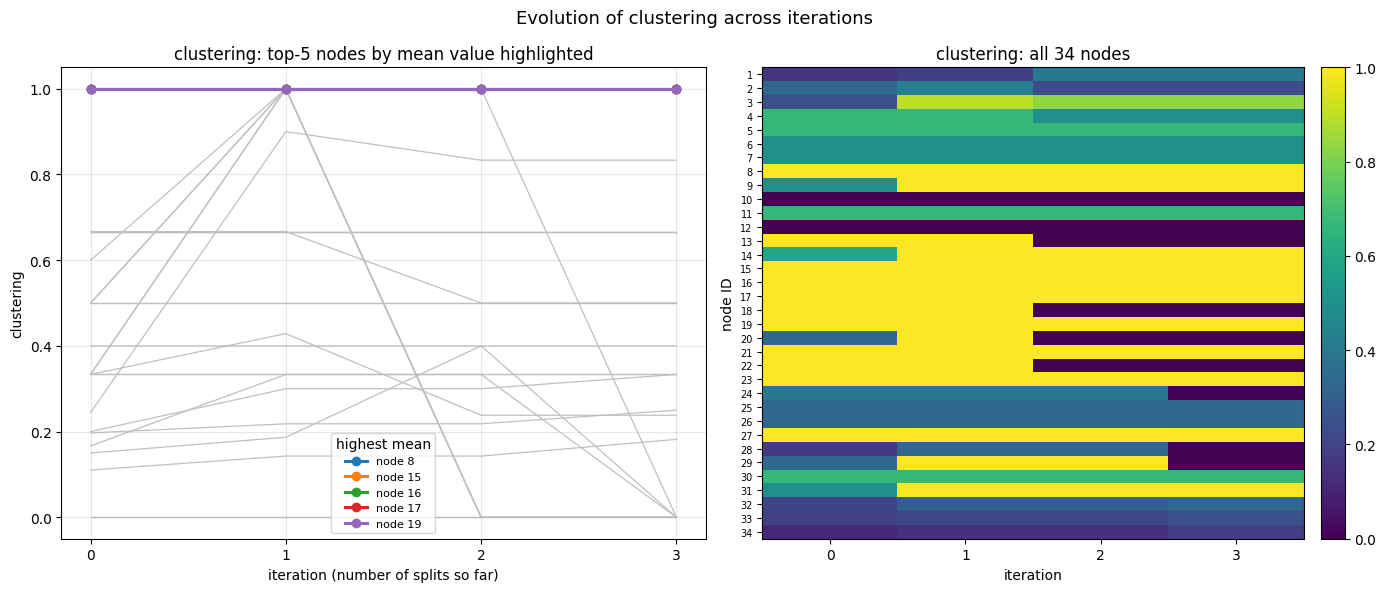

In [10]:
def plot_evolution(name):
    data = M[name]                                        # (n_iter, n)
    top = np.argsort(-data.mean(axis=0), kind="stable")[:5]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1.1, 1]})
    x = np.arange(n_iter)
    for i in nodes:
        if i not in top:
            ax1.plot(x, data[:, i], color="0.75", lw=0.9, zorder=1)
    for j, i in enumerate(top):
        ax1.plot(x, data[:, i], marker="o", lw=2.2, color=cmap(j), label=f"node {i + 1}", zorder=3)
    ax1.set_xticks(x)
    ax1.set_xlabel("iteration (number of splits so far)")
    ax1.set_ylabel(name)
    ax1.set_title(f"{name}: top-5 nodes by mean value highlighted")
    ax1.legend(title="highest mean", fontsize=8, loc="best")
    ax1.grid(alpha=0.3)

    im = ax2.imshow(data.T, aspect="auto", cmap="viridis")
    ax2.set_xticks(x); ax2.set_yticks(nodes)
    ax2.set_yticklabels([i + 1 for i in nodes], fontsize=7)
    ax2.set_xlabel("iteration"); ax2.set_ylabel("node ID")
    ax2.set_title(f"{name}: all 34 nodes")
    fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.03)
    fig.suptitle(f"Evolution of {name} across iterations", fontsize=13)
    fig.tight_layout()
    fig.savefig(f"assets/evolution_{name}.png", dpi=150)
    plt.show()

for name in METRICS:
    plot_evolution(name)

### Complete metric tables for all 34 nodes
For every iteration: degree centrality, betweenness centrality, closeness centrality and clustering coefficient of **every** node (node IDs 1–34), together with the id of the community the node belongs to at that iteration.

In [11]:
import pandas as pd

for t, h in enumerate(history):
    df = pd.DataFrame({
        "community":   [h["label"][i] for i in nodes],
        "degree":      h["metrics"]["degree"],
        "betweenness": h["metrics"]["betweenness"],
        "closeness":   h["metrics"]["closeness"],
        "clustering":  h["metrics"]["clustering"],
    }, index=pd.Index([i + 1 for i in nodes], name="node"))
    print(f"\n=== Iteration {t}: {len(h['parts'])} communities, Q = {h['Q']:.4f}  ({h['event']}) ===")
    print(df.round(4).to_string())


=== Iteration 0: 1 communities, Q = -0.0000  (whole graph (one community)) ===
      community  degree  betweenness  closeness  clustering
node                                                       
1             0  0.4848       0.4376     0.5690      0.1500
2             0  0.2727       0.0539     0.4853      0.3333
3             0  0.3030       0.1437     0.5593      0.2444
4             0  0.1818       0.0119     0.4648      0.6667
5             0  0.0909       0.0006     0.3793      0.6667
6             0  0.1212       0.0300     0.3837      0.5000
7             0  0.1212       0.0300     0.3837      0.5000
8             0  0.1212       0.0000     0.4400      1.0000
9             0  0.1515       0.0559     0.5156      0.5000
10            0  0.0606       0.0008     0.4342      0.0000
11            0  0.0909       0.0006     0.3793      0.6667
12            0  0.0303       0.0000     0.3667      0.0000
13            0  0.0606       0.0000     0.3708      1.0000
14            0  0.1

## 7. Discussion

### 7.1 What the method found
I applied recursive spectral bisection with Newman's subgroup matrix, following Newman (2006). The first split of the whole graph (λ₁ = 4.977, Q = 0.372) reproduces Zachary's recorded fission for 33 of 34 members. The only node on the other side is node 9: he belongs to Mr. Hi's faction in Zachary's records, but three of his five ties (to nodes 31, 33 and 34) go to the other group, so the graph structure alone pulls him across. Two more splits raise Q to 0.373 and then 0.393, and the recursion ends with **four communities**: {1, 5, 6, 7, 11, 12, 17}, {2, 3, 4, 8, 13, 14, 18, 20, 22}, {9, 10, 15, 16, 19, 21, 23, 27, 30, 31, 33, 34} and {24, 25, 26, 28, 29, 32}. I find the second split weak (ΔQ ≈ 0.001) and the third more convincing (ΔQ ≈ 0.021).

### 7.2 Why Newman's correction was necessary: node 12
On my first attempt I used the plain block of $B$ for each subgroup. The recursion gave five communities, or more accurately four proper communities plus a singleton community, node 12. Node 12 has degree 1 and its only neighbour is node 1, so it should not be a community on its own. The comparison run in Section 4 shows how it happens. At the second split the plain block puts node 12 in {5, 6, 7, 11, 12, 17}, away from node 1, so inside that group it has no ties at all. The plain block still reports λ₁ ≈ 2.15 > 0, so the stopping rule never fires, and at the fourth split node 12 is cut off alone. The recursion keeps splitting as long as some split lifts Q, even slightly (here 0.4081 → 0.4094). That is why the plain version ends at a higher Q (0.409) than the corrected one (0.393), but the extra gain comes from detaching a degree-1 node from its only neighbour, which says nothing about community structure.

The reason lies in Proposition 2 of the course handout (Section 5), which I verify numerically in Section 2 (max |B·1| ≈ 10⁻¹⁵). For the **whole-graph** matrix, $B\mathbf 1 = A\mathbf 1 - k\,(k^\top\mathbf 1)/2m = k - k = 0$, so $(\lambda = 0,\ u = \mathbf 1)$ is always an eigenpair. That is a property of the full matrix, not of an arbitrary group. For the plain block $B^{(C)}$ the row sums are $\sum_{l\in C}B_{il}$, which are generally non-zero, so $\mathbf 1$ need not be an eigenvector. Newman's correction, $B^{(C)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il}$, subtracts exactly those row sums on the diagonal, so $B^{(C)}\mathbf 1=\mathbf 0$ holds for **every** subgroup. Three consequences:

1. $\tfrac{1}{4m}s^\top B^{(C)}s$ is now the true modularity change $\Delta Q$ for splitting $C$ (this is the identity in Theorem 3 of the handout).
2. $0$ is always an eigenvalue, so $\lambda_1^{(C)}\ge 0$ and the rule "$\lambda_1\le 0 \Rightarrow$ indivisible" really means $\lambda_1=0$. In my run the 7-, 6- and 12-node groups all end with $\lambda_1 = 0$ to numerical precision. The leading eigenvector is then $\mathbf 1$, all its entries have the same sign, and the sign rule keeps every node together.
3. Node 12 now stays in the same community as node 1 ({1, 5, 6, 7, 11, 12, 17}), so no singleton is created.

One refinement of the rule: $\lambda_1>0$ only says that some *real-valued* vector would improve Q. It does not promise that rounding it to ±1 does. The 9-node group {2, 3, 4, 8, 13, 14, 18, 20, 22} has $\lambda_1 = 0.060>0$, but the sign split of its eigenvector has $\Delta Q = -0.016$. I therefore keep the guard that rejects a rounded split with $\Delta Q\le 0$, and that group is declared indivisible.

### 7.3 Which nodes stay central
Nodes **1** (Mr. Hi) and **34** (the club president) are the most robust hubs. They are in the top 5 for degree, betweenness and closeness at every iteration, and node **2** is in the degree top 5 throughout. Clustering behaves the opposite way: nodes 8, 15, 16, 17, 19, 21, 23 and 27 keep clustering 1.0 at every iteration. They sit inside tight groups and are peripheral, so the most clustered nodes are the least central.

### 7.4 How each metric evolves
Metrics are computed inside each community subgraph (iteration 0 is the full graph), so each value describes a node's role *within its group*.

| iter | communities | edges kept | Q | mean degree | mean betweenness | mean closeness | mean clustering |
|---|---|---|---|---|---|---|---|
| 0 | 1 | 78 | 0.000 | 0.139 | 0.044 | 0.426 | 0.571 |
| 1 | 2 | 68 | 0.372 | 0.251 | 0.057 | 0.556 | 0.684 |
| 2 | 3 | 59 | 0.373 | 0.325 | 0.079 | 0.588 | 0.560 |
| 3 | 4 | 52 | 0.393 | 0.398 | 0.102 | 0.627 | 0.512 |

**Degree centrality.** At iteration 0 the order is 34 (0.515, 17 ties), 1 (0.485, 16 ties), 33 (0.364), 3 (0.303), 2 (0.273). The first split cuts 10 edges, so nodes 1 and 34 each lose 2 ties but rise to 0.933 and 0.882 because the denominator shrinks from 33 to 15 and 17. At iteration 2 node 1 keeps only 5 ties (0.833) once the 9-node group is separated from it, while node 2 jumps to 0.875 (7 of 8 possible ties) as the centre of that group. At iteration 3 node 34 reaches 1.0, tied to all 11 other members of its community. The biggest rises are node 2 (0.273 → 0.875), nodes 6 and 7 (0.121 → 0.667) and node 26 (0.091 → 0.600). Absolute values are not comparable across iterations because the denominator is the community size, so I compare ranks: nodes 34, 1, 2 and 33 stay at the top.

**Betweenness centrality.** This is the metric that reacts most to the splits. The number of nodes with zero betweenness grows from 12 to 18. At iteration 0 the leaders are node 1 (0.438) and node 34 (0.304), followed by 33 (0.145) and 3 (0.144). Node 3 is the clearest example of a broker losing its role: he ties both factions together and falls to 0.002 after the first split and 0.012 at the end. Node 1 rises to 0.690 as the centre of the 16-node group and falls to 0.378 once that group splits. Node 2 has low betweenness globally (0.054) and 0.074 at iteration 1, then reaches 0.655 at iterations 2 and 3 as the connector inside the 9-node group. Node 32 goes from 0.138 to 0.113 and then to 0.400 inside {24, 25, 26, 28, 29, 32}, and node 4 rises from 0.012 to 0.262. Node 34 is stable at 0.570, 0.570 and then 0.564. Betweenness depends on the community in which it is measured.

**Closeness centrality.** Closeness rises almost everywhere because groups are smaller and more compact (mean 0.426 → 0.627). At iteration 0, nodes 1 (0.569), 3 (0.559), 34 (0.550) and 32 (0.541) lead. Nodes 3 and 32 are there because they bridge the factions, and they drop out of the top ranks once the groups separate (0.667 and 0.714 at the end). Node 34 rises from 0.550 to 0.895 and finally 1.0, and node 1 goes 0.569 → 0.938 → 0.857. Nodes 6 and 7 nearly double (0.384 → 0.750) when they join the compact 7-node group around node 1, and node 12 rises from 0.367 to 0.500 once it sits in a smaller group around its only neighbour.

**Clustering coefficient.** The mean rises from 0.571 to 0.684 after the first split, because the 10 removed edges are ties leading out of each group, so the neighbours that remain are more often connected to each other. Node 3 goes from 0.244 to 0.900, node 9 from 0.500 to 1.000, and node 1 from 0.150 to 0.187 and later 0.400. The mean then falls to 0.560 and 0.512, because the later splits cut through triangles and leave several nodes with a single remaining tie. By the end nine nodes have clustering 0, up from two (nodes 10 and 12) at the start. For example nodes 13, 18 and 22 are left with one neighbour inside the 9-node group once their tie to node 1 is cut.

### 7.5 Overall interpretation
Centrality in the full network mixes two roles that the splits pull apart. A **hub inside a faction** (nodes 1, 34, and locally node 2) keeps a high degree and closeness through every split. A **bridge between factions** (node 3, node 32) keeps a high betweenness only as long as the factions are joined, and loses it as soon as the cross-community ties are cut. The tightly knit periphery keeps clustering near 1 while contributing little to the other three metrics. So the community structure found by the recursion matches the real conflict, with Mr. Hi and the president anchoring the two sides.

### 7.6 Caveats
The recursion is greedy and has no refinement step, so neither the plain nor the corrected version is guaranteed to maximise Q globally. The metrics are computed on community-induced subgraphs, which can be disconnected inside, and NetworkX then uses its default (Wasserman–Faust) closeness scaling. Finally, the iteration-0 values are the full-graph metrics, which is why 1 and 34 dominate there.

*Reference:* M. E. J. Newman (2006). Modularity and community structure in networks. *PNAS*, 103(23), 8577–8582.

## 8. References
- M. E. J. Newman (2006). *Modularity and community structure in networks.* Proceedings of the National Academy of Sciences **103**(23): 8577–8582.
- W. W. Zachary (1977). *An information flow model for conflict and fission in small groups.* Journal of Anthropological Research **33**(4): 452–473.
- Course handout, *Modularity on the Karate Club Graph*, DSC212: Graph Theory Module.
- NetworkX documentation: `degree_centrality`, `betweenness_centrality`, `closeness_centrality`, `clustering`, `karate_club_graph`.